# Using active subspaces to explore discrepancies between global and local parameter sensitivities in a Lotka-Volterra system

__Huiyan Zou__, Department of Mathematical Sciences, Lafayette College, Easton, PA, USA

__Allison L. Lewis__, Department of Mathematical Sciences, Lafayette College, Easton, PA, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the six-parameter competitive Lotka–Volterra model of a two-population tumour spheroid in [[1]][R1]: the global active subspace of the total tumour burden, the paper's normalized activity scores (Table 1), and how far the active subspaces of small cells of the parameter cube are from the global one (the paper's Table 2 and Fig. 7, on fewer cells). It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later.

In [1]:
%matplotlib inline
import time
from itertools import permutations

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import tumour_model as tm

SEED = 246                        # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$r_S$', r'$r_R$', r'$K_S$', r'$K_R$', r'$\gamma_S$', r'$\gamma_R$']
short = ['rS', 'rR', 'KS', 'KR', 'gS', 'gR']


def order(v):
    """Order of magnitude of a rounding-level value (4.7e-13 -> '1e-13')."""
    return f'1e{int(np.floor(np.log10(abs(v))))}' if v != 0 else '0'


def rank_str(r):
    return ', '.join(short[j] for j in r)

### Summary

Zou and Lewis [[1]][R1] compare global sensitivity rankings of a six-parameter competitive Lotka–Volterra tumour model with rankings computed on small cells of the parameter cube, and measure how far each cell's active subspace is from the global one. We reimplement the model in Python with exact forward-sensitivity gradients, reproduce the paper's normalized activity scores (Table 1) to within 0.0025 and, on a random 1/64 of the paper's $8^6$ cells, its distribution of local–global subspace distances (Fig. 7 bin shares within 0.12 percentage points on the randomly drawn cells, mean 0.7305 against 0.7334) and its leading local rankings (Table 2). The global active subspace of the total tumour burden is four-dimensional ($\lambda_4/\lambda_5 = 8.97$, the only large eigenvalue ratio; a quadratic in four active variables has leave-one-out $R^2 = 0.917$), and the two interaction strengths span most of the two inactive directions.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[2]][R2].

### The model

The paper's Sec. 3.2.1 (Eqs. (3.1)–(3.2), p. 2186) models the volumes $S(t)$ and $R(t)$ (mm$^3$) of two competing tumour cell types, Type S and Type R, in a spheroid, after Cho et al. [[3]][R3]:

$$
\frac{dS}{dt} = r_S S\left(1 - \frac{S}{K_S} - \frac{\gamma_R R}{K_S}\right),\qquad
\frac{dR}{dt} = r_R R\left(1 - \frac{R}{K_R} - \frac{\gamma_S S}{K_R}\right),
$$

with growth rates $r_S, r_R$, carrying capacities $K_S, K_R$ and interaction strengths $\gamma_S, \gamma_R$. The initial total volume is 0.02 mm$^3$ in the ratio 9:1, so $S(0) = 0.018$ and $R(0) = 0.002$ mm$^3$ (p. 2187). Every input ranges over $[0, 1]$ ("positive growth scenarios with competitive interactions only", p. 2187), and the paper samples them uniformly (Latin hypercube designs, p. 2188). The paper prints no units for the inputs; with $S$, $R$ in mm$^3$ and $t$ in days they are 1/day for $r$, mm$^3$ for $K$, and dimensionless for $\gamma$.

**Quantities of interest.** The primary QoI is the total tumour burden over eight weeks, $q_{\mathrm{pri}} = \int_0^{56}(S + R)\,dt$ (Eq. (3.3), p. 2187), which the paper approximates "using the trapezoidal rule with bin sizes of one day"; this notebook uses exactly that discretised QoI, the trapezoidal rule on days $0, 1, \dots, 56$. The secondary QoI is the final Type S fraction $q_{\mathrm{sec}} = S(56)/(S(56) + R(56))$ (Eq. (3.5), p. 2198).

**Solver and gradients.** `tumour_model.py` integrates the equations in $u = \ln S$, $v = \ln R$ (so $u' = r_S(1 - (S + \gamma_R R)/K_S)$), which keeps both volumes positive and resolves a dying population to a relative accuracy; LSODA, rtol = atol = $10^{-10}$. The gradients are exact derivatives of the discretised QoIs up to the solver tolerance: the forward sensitivities $\partial(u, v)/\partial\mathbf x$ are integrated with the states (14 equations) and passed through the trapezoidal rule. The paper used forward differences with step $10^{-5}$ (p. 2188).

**$K = 0$.** The right-hand side divides by $K_S$ and $K_R$, so $K = 0$ is singular and the model raises an error there. Any $K > 0$ works: for $K$ much smaller than the initial volume the population collapses to about $K$ within a day (a stiff transient that LSODA handles), and the QoIs have finite limits as $K \to 0$ (`check_accuracy.py`, check 6). The probability of drawing exactly 0 from a continuous design is zero; the cell below prints the smallest values drawn.

The cell prints the inputs as the code declares them and draws the four trajectories of the paper's Fig. 3 (p. 2187).

input    units  range      description (source: Sec. 3.2.1, p. 2187)
r_S      1/day  [0, 1]     growth rate of Type S cells
r_R      1/day  [0, 1]     growth rate of Type R cells
K_S      mm^3   [0, 1]     carrying capacity of Type S cells
K_R      mm^3   [0, 1]     carrying capacity of Type R cells
gamma_S  -      [0, 1]     competitive effect of Type S on Type R
gamma_R  -      [0, 1]     competitive effect of Type R on Type S

S(0) = 0.018 mm^3, R(0) = 0.002 mm^3; days 0..56; LSODA in (ln S, ln R), rtol = 1e-10, atol = 1e-10


x = [0.36, 0.36, 0.85, 0.85, 0.3, 0.3]: q_pri = 56.1898 mm^3 day, q_sec = 0.5002, S(56) = 0.6541, R(56) = 0.6536 mm^3
x = [0.35, 0.5, 0.8, 0.95, 0.2, 0.45]: q_pri = 58.2850 mm^3 day, q_sec = 0.3206, S(56) = 0.4095, R(56) = 0.8681 mm^3
x = [0.01, 0.01, 0.8, 0.8, 0.6, 0.75]: q_pri = 1.4882 mm^3 day, q_sec = 0.8994, S(56) = 0.0309, R(56) = 0.0035 mm^3
x = [0.05, 0.08, 0.2, 0.5, 0.6, 0.75]: q_pri = 4.7608 mm^3 day, q_sec = 0.4954, S(56) = 0.0993, R(56) = 0.1011 mm^3


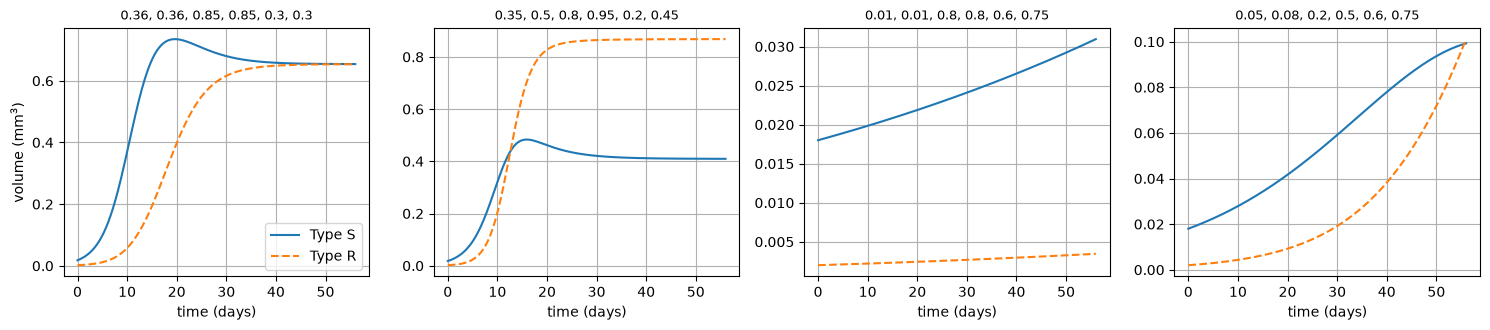

In [2]:
print(f"{'input':8s} {'units':6s} {'range':10s} description (source: Sec. 3.2.1, p. 2187)")
for j, n in enumerate(tm.NAMES):
    print(f'{n:8s} {tm.UNITS[j]:6s} [{tm.LOWER[j]:.0f}, {tm.UPPER[j]:.0f}]     {tm.DESCRIPTIONS[j]}')
print(f'\nS(0) = {tm.S0} mm^3, R(0) = {tm.R0} mm^3; days 0..{tm.T_END:.0f}; LSODA in (ln S, ln R), '
      f'rtol = {tm.RTOL:g}, atol = {tm.ATOL:g}')
fig3 = [[0.36, 0.36, 0.85, 0.85, 0.30, 0.30], [0.35, 0.50, 0.80, 0.95, 0.20, 0.45],
        [0.01, 0.01, 0.80, 0.80, 0.60, 0.75], [0.05, 0.08, 0.20, 0.50, 0.60, 0.75]]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
t = np.linspace(0, 56, 561)
for ax, x in zip(axes, fig3):
    Y = tm.trajectory(np.array(x))
    Yt = tm.trajectory(np.array(x), t=t)
    ax.plot(t, Yt[:, 0], 'C0-', label='Type S')
    ax.plot(t, Yt[:, 1], 'C1--', label='Type R')
    q = tm.qoi(np.array(x))
    ax.set_title(', '.join(f'{v:g}' for v in x), fontsize=9)
    ax.set_xlabel('time (days)')
    ax.grid(True)
    print(f'x = {x}: q_pri = {q[0]:.4f} mm^3 day, q_sec = {q[1]:.4f}, S(56) = {Y[-1, 0]:.4f}, R(56) = {Y[-1, 1]:.4f} mm^3')
axes[0].set_ylabel('volume (mm$^3$)')
axes[0].legend()
fig.tight_layout()
plt.close(fig)
fig

The trajectories match the four behaviours of the paper's Fig. 3: near-equal coexistence (panel 1, $S(56) = 0.6541$, $R(56) = 0.6536$ mm$^3$), Type R ahead (panel 2), slow growth that keeps the 9:1 ratio (panel 3, final Type S fraction 0.8994) and slow growth of both types to about 0.1 mm$^3$ each (panel 4, $S(56) = 0.0993$, $R(56) = 0.1011$ mm$^3$).

### Load data

`generate_data.py` wrote one file, `lv_samples.npz`, with two designs of 102,400 points each (seed 246; about 60 minutes of model runs, see `DATA.md`):

* **grid4**: every cell of a $4^6$ grid of the unit cube (4096 cells of width 0.25), 25 Latin-hypercube points in each cell. The paper uses $8^6 = 262{,}144$ cells of width 0.125 with 25 points each (p. 2187–2188); its full sweep is 6.5 million gradient evaluations, so this data set uses the coarser grid. Pooled, the 102,400 points are a uniform stratified sample of the cube, the design from which we estimate the global subspace, as the paper's sample code pools its local samples into the global one.
* **sub8**: 4096 of the paper's $8^6$ cells (the two cells named on p. 2201 and 4094 drawn at random without replacement), 25 Latin-hypercube points each. These cells have the paper's size, so their statistics estimate what the paper's full sweep would give, from a 1/64 random subset of its cells.

Each point stores the six inputs, $q_{\mathrm{pri}}$, $q_{\mathrm{sec}}$ and their gradients with respect to the inputs, `grad[i, k, j]` $= \partial q_k/\partial x_j$, and the flat index of its cell. The inputs and values are stored in double precision and the gradients in single precision (float32, a relative rounding below $10^{-7}$ per gradient row); we convert the gradients back to float64 on loading, so every computation below runs in double precision.

In [3]:
D = np.load('lv_samples.npz')
X4, f4, c4 = D['grid4_X'], D['grid4_f'], D['grid4_region']   # 4^6 cells of width 0.25
X8, f8, c8 = D['sub8_X'], D['sub8_f'], D['sub8_region']       # 4096 of the 8^6 cells of width 0.125
print(f"stored dtypes: X {D['grid4_X'].dtype}, f {D['grid4_f'].dtype}, grad {D['grid4_grad'].dtype}")
G4, G8 = D['grid4_grad'].astype(np.float64), D['sub8_grad'].astype(np.float64)   # stored as float32
print(f'grid4: X {X4.shape}, f {f4.shape}, grad {G4.shape}, {len(np.unique(c4))} cells')
print(f'sub8:  X {X8.shape}, f {f8.shape}, grad {G8.shape}, {len(np.unique(c8))} cells')

stored dtypes: X float64, f float64, grad float32
grid4: X (102400, 6), f (102400, 2), grad (102400, 2, 6), 4096 cells
sub8:  X (102400, 6), f (102400, 2), grad (102400, 2, 6), 4096 cells


We check the file against the model at five points and the gradients there against central differences (step $10^{-6}$), print the ranges of the inputs and outputs, and classify each point by its stable equilibrium (Table 3, p. 2196). For $\gamma_S, \gamma_R < 1$ the state $(K_S, 0)$ is stable when $\gamma_S K_S > K_R$ (the Jacobian eigenvalue $r_R(1 - \gamma_S K_S/K_R)$ is negative), $(0, K_R)$ when $\gamma_R K_R > K_S$, and the coexistence state otherwise; for independent uniform inputs on $[0,1]$, $P(\gamma_S K_S > K_R) = E[\gamma_S K_S] = 1/4$, so the exact shares are 25 %, 25 % and 50 %.

In [4]:
rows = [0, 1, 2, 3, 4]
f5 = tm.qois(X4[rows])
h = 1e-6
err = []
for i in rows:
    Gfd = np.column_stack([(tm.qoi(X4[i] + h * e) - tm.qoi(X4[i] - h * e)) / (2 * h) for e in np.eye(6)])
    err.append(np.linalg.norm(Gfd - G4[i], axis=1) / np.linalg.norm(G4[i], axis=1))
print(f'model vs file at grid4 rows {rows}: q_pri max rel diff {np.max(np.abs(f5[:, 0] - f4[rows, 0]) / f4[rows, 0]):.1e}, '
      f'q_sec max abs diff {np.max(np.abs(f5[:, 1] - f4[rows, 1])):.1e}')
print(f'gradients vs central differences (h = {h:g}): max rel error q_pri {np.max(err, axis=0)[0]:.1e}, q_sec {np.max(err, axis=0)[1]:.1e}')
for name, X, f in (('grid4', X4, f4), ('sub8', X8, f8)):
    print(f'{name}: inputs in [{X.min():.2e}, {X.max():.6f}]; smallest K_S, K_R {X[:, 2].min():.2e}, {X[:, 3].min():.2e}; '
          f'q_pri in [{f[:, 0].min():.4f}, {f[:, 0].max():.3f}] mm^3 day; q_sec in [{f[:, 1].min():.1e}, {f[:, 1].max():.6f}]; '
          f'q_sec < 1e-6: {(f[:, 1] < 1e-6).sum()}, > 1 - 1e-6: {(f[:, 1] > 1 - 1e-6).sum()} '
          f'(together {((f[:, 1] < 1e-6) | (f[:, 1] > 1 - 1e-6)).sum()})')
# Long-term outcome (Table 3, p. 2196): (K_S, 0) stable if gamma_S K_S > K_R, (0, K_R) if gamma_R K_R > K_S, else coexistence
for name, X in (('grid4', X4), ('sub8', X8)):
    exS = X[:, 4] * X[:, 2] > X[:, 3]
    exR = X[:, 5] * X[:, 3] > X[:, 2]
    print(f'{name}: (0, K_R) {100 * exR.mean():.2f} %, (K_S, 0) {100 * exS.mean():.2f} %, '
          f'coexistence {100 * (~exS & ~exR).mean():.2f} %, both {int((exS & exR).sum())}')

model vs file at grid4 rows [0, 1, 2, 3, 4]: q_pri max rel diff 1.4e-09, q_sec max abs diff 3.4e-11
gradients vs central differences (h = 1e-06): max rel error q_pri 4.7e-08, q_sec 4.5e-08
grid4: inputs in [3.72e-06, 0.999998]; smallest K_S, K_R 5.40e-05, 9.43e-06; q_pri in [0.1333, 91.198] mm^3 day; q_sec in [0.0e+00, 1.000000]; q_sec < 1e-6: 12354, > 1 - 1e-6: 14319 (together 26673)
sub8: inputs in [2.82e-06, 0.999998]; smallest K_S, K_R 1.14e-05, 4.48e-06; q_pri in [0.1421, 88.780] mm^3 day; q_sec in [0.0e+00, 1.000000]; q_sec < 1e-6: 12060, > 1 - 1e-6: 13834 (together 25894)
grid4: (0, K_R) 25.03 %, (K_S, 0) 24.94 %, coexistence 50.03 %, both 0
sub8: (0, K_R) 24.97 %, (K_S, 0) 24.14 %, coexistence 50.89 %, both 0


The model reproduces the stored values to a relative $1.4\times10^{-9}$ ($q_{\mathrm{pri}}$) and $3.4\times10^{-11}$ (absolute, $q_{\mathrm{sec}}$): the files come from the solve with sensitivities (14 equations) and the check uses the solve without them, so they agree to the solver tolerance. The gradients agree with central differences to $4.7\times10^{-8}$ and $4.5\times10^{-8}$ at these five points, the size of the float32 storage rounding (`check_accuracy.py` checks 100 points and a tighter solve). The smallest carrying capacities drawn are $5.4\times10^{-5}$ ($K_S$) and $9.4\times10^{-6}$ ($K_R$) in grid4, so every point is inside the model's domain $K > 0$. $q_{\mathrm{sec}}$ is within $10^{-6}$ of 0 or 1 at 26,673 of the 102,400 grid4 points (12,354 near 0 and 14,319 near 1) (one population has practically died out by day 56); its gradient there is tiny, which matters for the local analysis of $q_{\mathrm{sec}}$ below. The long-term outcomes split 25.03 %, 24.94 % and 50.03 % in grid4, the exact 25 %, 25 %, 50 % within sampling error; the paper's Table 3 has 25 %, 25 %, 50 % of its 6,553,600 samples.

### Estimate the subspace

The model is cheap and smooth and we have exact gradients, so we use the gradient-based estimator (`estimator="as"`) on the 102,400 pooled grid4 points, $\hat{\mathbf C} = \frac1M\sum_i\nabla q_i\nabla q_i^T$. The input space is `ac.Uniform` on $[0,1]^6$; the library maps the inputs to $[-1,1]^6$, which multiplies every gradient by the same factor 1/2, so eigenvectors, eigenvalue ratios and normalized activity scores are those of the paper's $[0,1]$ coordinates. We use 200 bootstrap replicates and orient every eigenvector so that $q_{\mathrm{pri}}$ increases along it (positive covariance of $q$ with $\mathbf w_k^T\mathbf x$; the paper shows no eigenvectors).

In [5]:
space = ac.Uniform(tm.LOWER, tm.UPPER, names=tm.NAMES)
sub = ac.active_subspace(space=space, X=X4, f=f4[:, 0], grads=G4[:, 0], estimator='as', nboot=200, rng=SEED)
sub = ac.orient(sub, by='covariance', X=X4, f=f4[:, 0], columns=6)
lam = sub.eigenvalues
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
b = sub.bootstrap_eigenvalues
print(f'q_pri eigenvalues {np.array2string(lam, precision=4)}')
print('ratios lambda_k/lambda_k+1: ' + ', '.join(f'{lam[k] / lam[k + 1]:.2f} '
      f'[{np.percentile(b[:, k] / b[:, k + 1], 2.5):.2f}, {np.percentile(b[:, k] / b[:, k + 1], 97.5):.2f}]' for k in range(5)))
print(f'gap rule (evg) picks n = {k_hat}; share of the trace in lambda_1..k: ' +
      ', '.join(f'{np.sum(lam[:k + 1]) / np.sum(lam):.4f}' for k in range(6)))

q_pri eigenvalues [491.9979 229.7035 160.9953 127.9621  14.2584   6.5069]
ratios lambda_k/lambda_k+1: 2.14 [2.11, 2.18], 1.43 [1.39, 1.46], 1.26 [1.25, 1.27], 8.97 [8.85, 9.10], 2.19 [2.16, 2.23]
gap rule (evg) picks n = 1; share of the trace in lambda_1..k: 0.4770, 0.6997, 0.8558, 0.9799, 0.9937, 1.0000


### Results

**Eigenvalues and subspace errors** (95 % bootstrap bands).

bootstrap mean subspace distance: n = 1: 0.00783, n = 2: 0.00961, n = 3: 0.0213, n = 4: 0.00174, n = 5: 0.0052


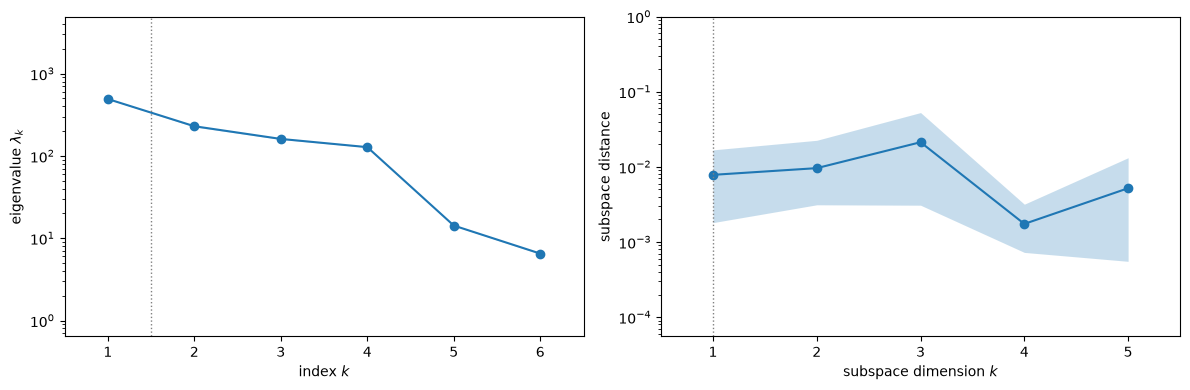

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ac.plotting.plot_eigenvalues(sub, ax=axes[0])
ac.plotting.plot_subspace_errors(sub, ax=axes[1])
fig.tight_layout()
plt.close(fig)
print('bootstrap mean subspace distance: ' + ', '.join(f'n = {k + 1}: {d:.3g}' for k, d in enumerate(sub.bootstrap_distances.mean(axis=0))))
fig

The eigenvalues are 492.0, 229.7, 161.0, 128.0, 14.26 and 6.51. The ratios of consecutive eigenvalues are 2.14, 1.43, 1.26, **8.97** and 2.19, each with a narrow bootstrap interval (8.85–9.10 for $\lambda_4/\lambda_5$), so the spectrum has one clear gap, after the fourth eigenvalue; the first four eigenvalues carry 0.9799 of the trace. The library's default rule (largest linear gap, `evg`) picks $n = 1$ because $\lambda_1 - \lambda_2$ is the largest absolute difference, but $\lambda_1/\lambda_2 = 2.14$ is not a gap in the usual sense. The bootstrap subspace distance is smallest for $n = 4$ (0.00174, against 0.00783 for $n = 1$ and 0.0213 for $n = 3$), but with 102,400 gradients every candidate subspace is estimated well, so the error plot alone separates the candidates only weakly; the gap and the surrogates below do most of the work. The paper's own rule for a cell's dimension, the smallest $n$ whose eigenvalues capture more than 95 % of the trace (Sec. 2.3, p. 2184), applied to the global matrix also gives $n = 4$: the shares printed above are 0.8558 for $n = 3$ and 0.9799 for $n = 4$. We check the candidates with quadratic surrogates.

In [7]:
loo = {}
for n in range(1, 6):
    s = ac.fit_surrogate(X=X4, f=f4[:, 0], subspace=ac.with_dimension(sub, n), kind='poly', degree=2)
    loo[n] = s.loo_r_squared
print('quadratic surrogate in n active variables, LOO R^2: ' + ', '.join(f'n = {n}: {v:.4f}' for n, v in loo.items()))
s3 = ac.fit_surrogate(X=X4, f=f4[:, 0], subspace=ac.with_dimension(sub, 4), kind='poly', degree=3)
print(f'cubic in n = 4: LOO R^2 = {s3.loo_r_squared:.4f}')

quadratic surrogate in n active variables, LOO R^2: n = 1: 0.7011, n = 2: 0.7837, n = 3: 0.8264, n = 4: 0.9170, n = 5: 0.9291


cubic in n = 4: LOO R^2 = 0.9588


**Dimension.** A quadratic in the active variables has leave-one-out $R^2$ 0.7011, 0.7837, 0.8264, **0.9170** and 0.9291 for $n = 1, \dots, 5$: the largest step is from three to four variables, and a fifth raises it only to 0.9291. A cubic in four variables reaches 0.9588, so the remaining misfit is mostly the polynomial's, not the subspace's. We take $n = 4$: it is the only gap in the spectrum ($8.97$, bootstrap interval $[8.85, 9.10]$), it is where the leave-one-out $R^2$ makes its largest step, it is what the paper's 95 % trace rule gives, and the two left-out eigenvalues carry the remaining $1 - 0.9799$ of the trace. The function is not low-dimensional in the one- or two-variable sense; what the subspace removes is the two interaction strengths, as the eigenvectors show.

w1 = [ 0.521  0.367  0.592  0.461 -0.136 -0.112]
w2 = [-0.853  0.218  0.387  0.254 -0.079 -0.067]
w3 = [ 0.021 -0.77   0.605 -0.198 -0.007 -0.03 ]
w4 = [-0.024 -0.474 -0.344  0.802 -0.093 -0.068]
w5 = [0.001 0.014 0.123 0.201 0.766 0.598]
w6 = [-0.001 -0.011  0.018 -0.003 -0.616  0.787]


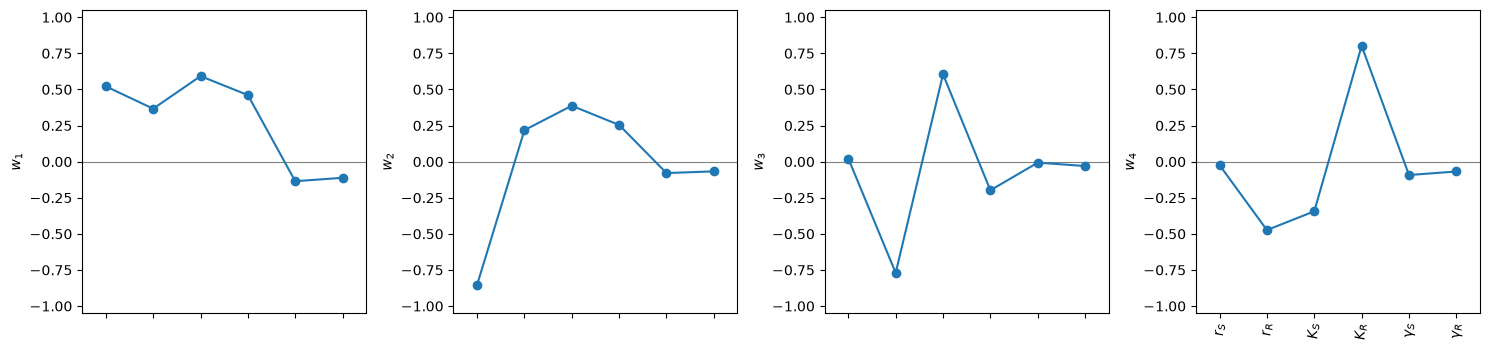

In [8]:
N_CHOSEN = 4
sub = ac.with_dimension(sub, N_CHOSEN)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
ac.plotting.plot_eigenvectors(sub, indices=[0, 1, 2, 3], labels=labels, ax=list(axes))
fig.tight_layout()
plt.close(fig)
for k in range(6):
    print(f'w{k + 1} = {np.array2string(sub.W[:, k], precision=3, suppress_small=True)}')
fig

$\mathbf w_1 = (0.521, 0.367, 0.592, 0.461, -0.136, -0.112)$: the burden rises with both growth rates and both carrying capacities and falls with the interaction strengths, with the Type S parameters weighted more (the tumour starts 90 % Type S). $\mathbf w_2$ is dominated by $r_S$ ($-0.853$) against the carrying capacities, and $\mathbf w_3$, $\mathbf w_4$ contrast $r_R$, $K_S$ and $K_R$. The inactive directions are almost purely the interactions: $\mathbf w_5 = (0.001, 0.014, 0.123, 0.201, 0.766, 0.598)$ and $\mathbf w_6 = (-0.001, -0.011, 0.018, -0.003, -0.616, 0.787)$.

corr(y1, q_pri) = 0.8368; y1 in [-1.99, 1.90]


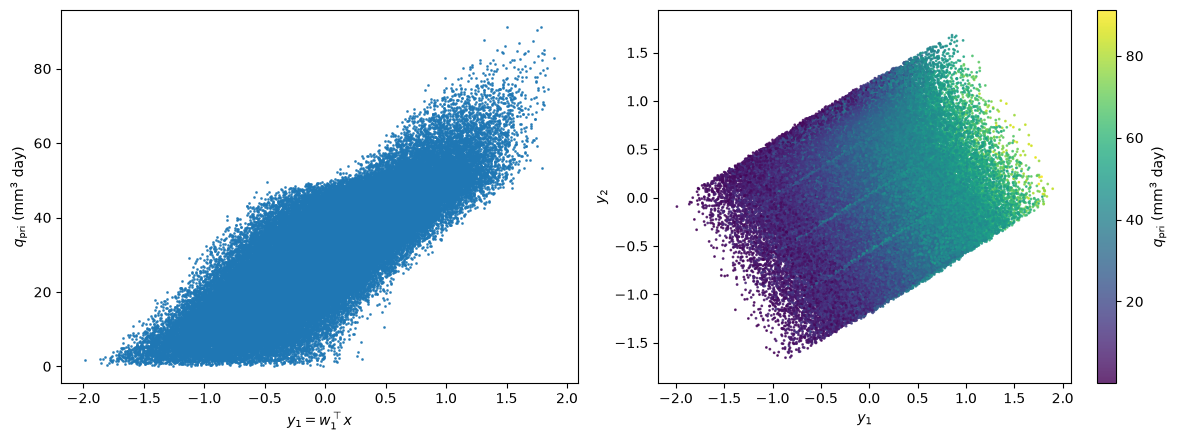

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sub, X=X4, f=f4[:, 0], dims=1, qoi_label=r'$q_{\mathrm{pri}}$ (mm$^3$ day)', ax=axes[0])
ac.plotting.plot_sufficient_summary(sub, X=X4, f=f4[:, 0], dims=2, qoi_label=r'$q_{\mathrm{pri}}$ (mm$^3$ day)', ax=axes[1])
for c in axes[0].collections:
    c.set_sizes([1])
for c in axes[1].collections:
    c.set_sizes([1])
fig.tight_layout()
plt.close(fig)
XN4 = space.to_normalized(X4)
y = XN4 @ sub.W
print(f'corr(y1, q_pri) = {np.corrcoef(y[:, 0], f4[:, 0])[0, 1]:.4f}; y1 in [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]')
fig

The one-dimensional summary plot shows a clear increasing trend with large scatter ($\mathrm{corr}(y_1, q_{\mathrm{pri}}) = 0.8368$), as expected with $\lambda_1/\lambda_2 = 2.14$; the two-dimensional plot shows a colour gradient along both $y_1$ and $y_2$.

#### Global activity scores (Table 1)

The paper's activity score (Eq. (2.2), p. 2183) sums over **all** $m$ eigenpairs, $\alpha_i = \sum_{j=1}^m\lambda_j w_{ij}^2$, which equals the diagonal entry $C_{ii}$, the mean squared partial derivative; Table 1 reports $\alpha_i/\alpha_{\max}$. (The activity scores of Constantine and Diaz [[4]][R4] sum over the first $n$ eigenpairs; the cell prints those too, for $n = 4$.) We compute the paper's scores from grid4 with a 200-replicate bootstrap over points, and from sub8 with a bootstrap over cells, because sub8's 25 points per cell form clusters in a random subset of cells.

In [10]:
def act_scores(G):
    """Eq. (2.2) of the paper with all m eigenpairs: alpha_i = sum_j lambda_j w_ij^2 = C_ii, normalized by the max."""
    a = np.mean(G ** 2, axis=0)
    return a / a.max()

paper_alpha = np.array([1.0000, 0.6715, 0.9364, 0.6942, 0.0746, 0.0567])   # Table 1, p. 2188
a_lib = ac.activity_scores(sub, n=6)
a4, a8 = act_scores(G4[:, 0]), act_scores(G8[:, 0])
rng = np.random.default_rng(SEED)
boot = np.array([act_scores(G4[rng.integers(0, len(G4), len(G4)), 0]) for _ in range(200)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
# sub8 is a random subset of cells, so its 25 points per cell are a cluster: resample whole cells
Gc8 = G8[:, 0].reshape(-1, 25, 6)
boot8 = np.array([act_scores(Gc8[rng.integers(0, len(Gc8), len(Gc8))].reshape(-1, 6)) for _ in range(200)])
lo8, hi8 = np.percentile(boot8, [2.5, 97.5], axis=0)
print(f"{'input':8s} {'paper':>7s} {'grid4':>7s} {'95 % bootstrap':>17s} {'sub8':>7s} {'95 % (cells)':>17s} {'library':>8s}")
for j in range(6):
    print(f'{tm.NAMES[j]:8s} {paper_alpha[j]:7.4f} {a4[j]:7.4f}   [{lo[j]:.4f}, {hi[j]:.4f}] {a8[j]:7.4f}   '
          f'[{lo8[j]:.4f}, {hi8[j]:.4f}] {a_lib[j] / a_lib.max():8.4f}')
print(f'largest |grid4 - paper| = {np.max(np.abs(a4 - paper_alpha)):.4f}')
glob_rank = np.argsort(-a4)
print(f'global ranking (grid4): {rank_str(glob_rank)}; sub8: {rank_str(np.argsort(-a8))}; paper: rS, KS, KR, rR, gS, gR')
alpha_n = ac.activity_scores(sub, n=N_CHOSEN)
print(f'activity scores with n = {N_CHOSEN} eigenpairs (normalized by max): {np.array2string(alpha_n / alpha_n.max(), precision=4)}')

input      paper   grid4    95 % bootstrap    sub8      95 % (cells)  library
r_S       1.0000  1.0000   [1.0000, 1.0000]  1.0000   [0.9313, 1.0000]   1.0000
r_R       0.6715  0.6690   [0.6454, 0.6940]  0.7125   [0.6327, 0.7804]   0.6690
K_S       0.9364  0.9347   [0.9125, 0.9632]  0.9815   [0.8904, 1.0000]   0.9347
K_R       0.6942  0.6934   [0.6756, 0.7151]  0.7415   [0.6644, 0.7838]   0.6934
gamma_S   0.0746  0.0745   [0.0726, 0.0771]  0.0800   [0.0705, 0.0855]   0.0745
gamma_R   0.0567  0.0568   [0.0551, 0.0587]  0.0646   [0.0569, 0.0700]   0.0568
largest |grid4 - paper| = 0.0025
global ranking (grid4): rS, KS, KR, rR, gS, gR; sub8: rS, KS, KR, rR, gS, gR; paper: rS, KS, KR, rR, gS, gR
activity scores with n = 4 eigenpairs (normalized by max): [1.     0.669  0.934  0.6915 0.0385 0.0264]


The grid4 scores are 1.0000, 0.6690, 0.9347, 0.6934, 0.0745, 0.0568 for $r_S, r_R, K_S, K_R, \gamma_S, \gamma_R$; the paper's Table 1 values lie inside every 95 % interval, and the largest difference is 0.0025 ($r_R$). The ranking is the paper's, $r_S, K_S, K_R, r_R, \gamma_S, \gamma_R$. The sub8 estimate (0.7125, 0.9815, 0.7415, … for $r_R$, $K_S$, $K_R$) is noisier: its cell-level intervals, printed beside it, are wider and contain the grid4 values except for $\gamma_R$ (0.0568, just below the interval's lower end 0.0569). The scores with $n = 4$ eigenpairs keep the four main parameters and halve the interaction scores (0.0385, 0.0264), because most of the interactions' weight sits in the two discarded directions.

#### Local analysis (Table 2)

For each cell we follow the paper's Sec. 2.3 (p. 2184) and its sample code: the cell's matrix $\tilde{\mathbf C}$ from its 25 gradients, its dimension $n$ as the smallest number of eigenvalues that captures more than 95 % of the trace, the distance $\lVert\mathbf W_1\mathbf W_1^T - \tilde{\mathbf W}_1\tilde{\mathbf W}_1^T\rVert_2$ (Eq. (2.3)) between the global and local subspaces of that dimension, and the ranking of the inputs by the cell's activity scores (Eq. (2.2)). The paper's "local analysis" means exactly this, global metrics on a subregion (Remark, p. 2184). We do it for the 4096 grid4 cells (width 0.25) and the 4096 sub8 cells (width 0.125, the paper's size).

In [11]:
def local_analysis(G, W, M=25):
    """Per cell: C from the cell's M gradients, its eigenpairs, the dimension n that first captures
    more than 95 % of the trace (Sec. 2.3, p. 2184), the distance (2.3) to the global span of W[:, :n],
    and the ranking of the inputs by the cell's activity scores (Eq. 2.2, all m eigenpairs)."""
    Gc = G.reshape(-1, M, G.shape[1])
    C = np.einsum('rmi,rmj->rij', Gc, Gc) / M
    lam_l, W_l = np.linalg.eigh(C)
    lam_l, W_l = lam_l[:, ::-1], W_l[:, :, ::-1]
    trace = lam_l.sum(axis=1)
    flat = trace <= 1e-12 * np.median(trace)   # cells where the QoI is flat to rounding: no subspace
    energy = np.cumsum(lam_l, axis=1) / np.where(flat, 1.0, trace)[:, None]
    n_l = np.where(flat, 0, np.argmax(energy > 0.95, axis=1) + 1)
    dist = np.empty(len(C))
    for r, n in enumerate(n_l):
        if n == 0:
            dist[r] = np.nan
            continue
        P = W[:, :n] @ W[:, :n].T - W_l[r, :, :n] @ W_l[r, :, :n].T
        dist[r] = np.linalg.norm(P, 2)
    alpha = np.einsum('rii->ri', C)
    return dict(n=n_l, dist=dist, rank=np.argsort(-alpha, axis=1), alpha=alpha, flat=flat)


def ranking_table(rank, top=10):
    u, cnt = np.unique(rank, axis=0, return_counts=True)
    o = np.argsort(-cnt, kind='stable')
    return u[o[:top]], cnt[o[:top]], u, cnt


W_glob = sub.W           # signs do not matter for the distance
L4 = local_analysis(G4[:, 0], W_glob)
L8 = local_analysis(G8[:, 0], W_glob)
for name, L in (('grid4 (4^6 cells)', L4), ('sub8 (4096 of 8^6 cells)', L8)):
    top, cnt, u, call = ranking_table(L['rank'])
    pos = [i for i, r in enumerate(u[np.argsort(-call, kind='stable')]) if np.array_equal(r, glob_rank)]
    where = f'{pos[0] + 1}' if pos else 'not observed'
    nglob = int(np.sum(np.all(L['rank'] == glob_rank, axis=1)))
    print(f'\n{name}: {len(u)} distinct rankings of {len(L["rank"])} cells; the global ranking is number {where} '
          f'({nglob} cells, {100 * nglob / len(L["rank"]):.2f} %); local n counts (1..6) {np.bincount(L["n"], minlength=7)[1:]}; '
          f'flat cells {int(L["flat"].sum())}')
    for i in range(10):
        print(f'  {i + 1:2d}. {rank_str(top[i]):24s} {cnt[i]:5d} ({100 * cnt[i] / len(L["rank"]):.2f} %)')


grid4 (4^6 cells): 188 distinct rankings of 4096 cells; the global ranking is number 27 (48 cells, 1.17 %); local n counts (1..6) [1799 2105  184    8    0    0]; flat cells 0
   1. KS, rS, KR, gS, rR, gR     152 (3.71 %)
   2. KR, rR, KS, gS, gR, rS     147 (3.59 %)
   3. KS, rS, KR, gS, gR, rR     119 (2.91 %)
   4. rS, KR, KS, gS, gR, rR     113 (2.76 %)
   5. rR, KS, KR, gS, gR, rS     104 (2.54 %)
   6. rS, rR, KS, KR, gS, gR      97 (2.37 %)
   7. KR, KS, rR, gR, gS, rS      96 (2.34 %)
   8. KS, KR, gS, rS, gR, rR      88 (2.15 %)
   9. KR, KS, gR, rR, gS, rS      88 (2.15 %)
  10. KS, KR, gS, gR, rS, rR      78 (1.90 %)

sub8 (4096 of 8^6 cells): 230 distinct rankings of 4096 cells; the global ranking is number 41 (28 cells, 0.68 %); local n counts (1..6) [3309  775   12    0    0    0]; flat cells 0
   1. KR, rR, KS, gS, gR, rS     179 (4.37 %)
   2. KS, rS, KR, gS, rR, gR     149 (3.64 %)
   3. KS, rS, KR, gS, gR, rR     149 (3.64 %)
   4. KS, rS, KR, gR, gS, rR     133 (3.2

The local rankings vary widely. On the sub8 cells the most frequent ranking is $K_R, r_R, K_S, \gamma_S, \gamma_R, r_S$ in 4.37 % of cells, the paper's most frequent ranking (12,311 of 262,144 cells, 4.70 %, Table 2); the paper's second, third and fourth rankings ($K_S, r_S, K_R$ followed by $\gamma_S, \gamma_R, r_R$; by $\gamma_S, r_R, \gamma_R$; by $\gamma_R, \gamma_S, r_R$; 3.96 %, 3.56 %, 3.42 %) are our third, second and fourth (3.64 %, 3.64 %, 3.25 %). The global ranking appears in only 0.68 % of the sub8 cells (41st most frequent), against 1525 cells (0.58 %, 53rd) in the paper (p. 2188). We see 230 distinct rankings in 4096 sub8 cells; the paper's 304 are counted over 64 times as many cells and are not comparable. On the larger grid4 cells the global ranking is more common (1.17 %, 27th) and the local dimension is larger (2105 cells with $n = 2$ against 775 in sub8), since a larger cell averages over more variation in the gradient.

grid4 top 1: rS 12.5 %, rR 12.4 %, KS 44.1 %, KR 30.9 %, gS 0.0 %, gR 0.0 %
grid4 top 2: rS 32.4 %, rR 31.9 %, KS 69.4 %, KR 62.2 %, gS 2.2 %, gR 1.9 %
grid4 top 3: rS 42.6 %, rR 45.6 %, KS 93.6 %, KR 86.5 %, gS 19.1 %, gR 12.6 %
sub8 top 1: rS 11.4 %, rR 11.0 %, KS 44.6 %, KR 32.9 %, gS 0.1 %, gR 0.0 %
sub8 top 2: rS 34.1 %, rR 32.1 %, KS 68.9 %, KR 59.5 %, gS 3.1 %, gR 2.3 %
sub8 top 3: rS 44.5 %, rR 45.3 %, KS 90.2 %, KR 86.1 %, gS 18.6 %, gR 15.4 %


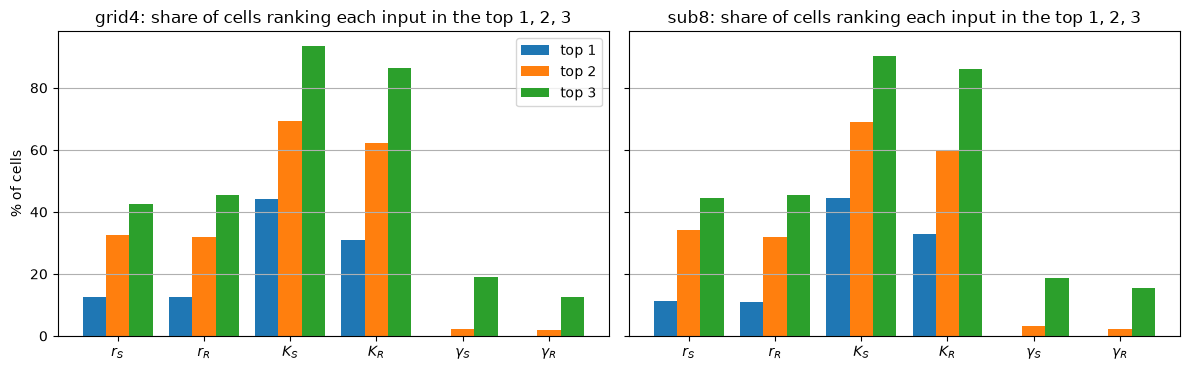

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, L) in zip(axes, (('grid4', L4), ('sub8', L8))):
    for k in range(3):
        share = [100 * np.mean(np.any(L['rank'][:, :k + 1] == j, axis=1)) for j in range(6)]
        ax.bar(np.arange(6) + (k - 1) * 0.27, share, width=0.27, label=f'top {k + 1}')
        print(f'{name} top {k + 1}: ' + ', '.join(f'{short[j]} {s:.1f} %' for j, s in enumerate(share)))
    ax.set_xticks(range(6))
    ax.set_xticklabels(labels)
    ax.set_title(f'{name}: share of cells ranking each input in the top 1, 2, 3')
    ax.grid(True, axis='y')
axes[0].set_ylabel('% of cells')
axes[0].legend()
fig.tight_layout()
plt.close(fig)
fig

As in the paper's Fig. 4 (p. 2190, no numbers printed), a carrying capacity is most often the top-ranked input ($K_S$ in 44.6 % and $K_R$ in 32.9 % of the sub8 cells), the growth rates are first less often (11.4 % and 11.0 %) but are often in the top three, and the interaction strengths are almost never first (0.1 % and 0.0 %) but are in the top three in 18.6 % and 15.4 % of cells.

#### Local–global subspace distances (Figs. 5 and 7)

The cell prints the distribution of distances in the paper's five bins of width 0.2, the two cells the paper uses for its surrogate experiment (p. 2201), and draws the distances against each input's bin, as in the paper's Fig. 5 (box: quartiles; red: bin means).

grid4 (all 4096 cells): mean distance 0.82183, median 0.8390; cells per 0.2-bin [6, 60, 421, 1298, 2311] = 0.146, 1.465, 10.278, 31.689, 56.421 %
sub8 (all 4096 cells): mean distance 0.73040, median 0.7391; cells per 0.2-bin [2, 72, 704, 2078, 1240] = 0.049, 1.758, 17.188, 50.732, 30.273 %
sub8 (4094 random cells): mean distance 0.73048, median 0.7391; cells per 0.2-bin [1, 72, 704, 2078, 1239] = 0.024, 1.759, 17.196, 50.757, 30.264 %
paper (8^6 cells): [63, 4362, 44939, 133127, 79653] = 0.024, 1.664, 17.143, 50.784, 30.385 %; mean 0.7334 (p. 2197)
largest |share difference|, random sub8 cells vs paper: 0.12 percentage points
cell (1, 2, 3, 4, 1, 4) (lower corner [0.125 0.25  0.375 0.5   0.125 0.5  ]): local n = 1, distance 0.1332 (paper 0.1355, p. 2201)
cell (7, 7, 7, 7, 7, 7) (lower corner [0.875 0.875 0.875 0.875 0.875 0.875]): local n = 2, distance 0.9997 (paper 0.9996, p. 2201)
$r_S$        grid4 bin means: 0.793, 0.806, 0.839, 0.850
$r_R$        grid4 bin means: 0.862, 0.831, 0.7

$\gamma_S$   grid4 bin means: 0.788, 0.810, 0.838, 0.851
$\gamma_R$   grid4 bin means: 0.795, 0.814, 0.831, 0.848


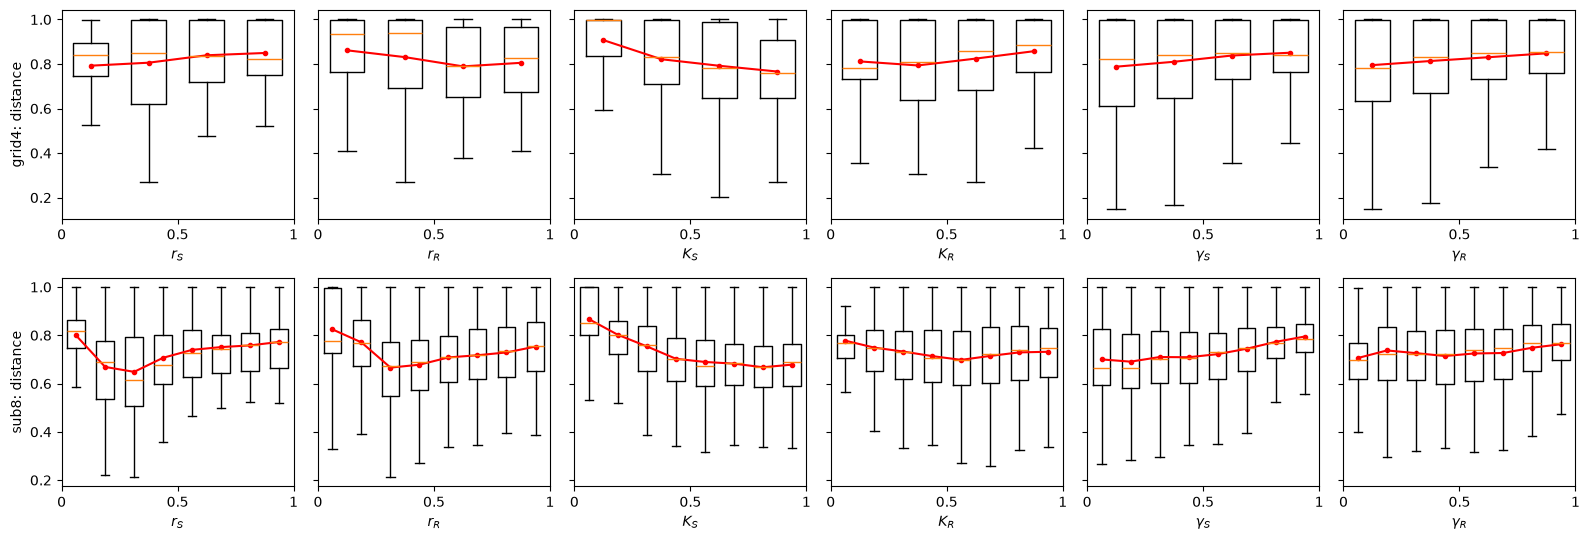

In [13]:
paper_bins = np.array([63, 4362, 44939, 133127, 79653])      # p. 2192
edges = np.linspace(0, 1, 6)
named = [np.ravel_multi_index(c, (8,) * 6) for c in [(1, 2, 3, 4, 1, 4), (7, 7, 7, 7, 7, 7)]]
cells8 = c8[::25]
rand8 = ~np.isin(cells8, named)       # the 4094 cells drawn at random (the two named cells were added by hand)
for name, d in (('grid4 (all 4096 cells)', L4['dist']), ('sub8 (all 4096 cells)', L8['dist']),
                (f'sub8 ({int(rand8.sum())} random cells)', L8['dist'][rand8])):
    cnt_b = np.histogram(d, bins=edges)[0]
    print(f'{name}: mean distance {d.mean():.5f}, median {np.median(d):.4f}; cells per 0.2-bin '
          f'{cnt_b.tolist()} = ' + ', '.join(f'{v:.3f}' for v in 100 * cnt_b / cnt_b.sum()) + ' %')
print(f'paper (8^6 cells): {paper_bins.tolist()} = ' + ', '.join(f'{v:.3f}' for v in 100 * paper_bins / paper_bins.sum())
      + ' %; mean 0.7334 (p. 2197)')
cnt_r = np.histogram(L8['dist'][rand8], bins=edges)[0]
print(f'largest |share difference|, random sub8 cells vs paper: '
      f'{np.max(np.abs(100 * cnt_r / cnt_r.sum() - 100 * paper_bins / paper_bins.sum())):.2f} percentage points')
for c, pv in zip(named, (0.1355, 0.9996)):
    r = int(np.nonzero(cells8 == c)[0][0])
    print(f'cell {tuple(int(i) for i in np.unravel_index(c, (8,) * 6))} (lower corner {np.array(np.unravel_index(c, (8,) * 6)) / 8}): '
          f'local n = {L8["n"][r]}, distance {L8["dist"][r]:.4f} (paper {pv}, p. 2201)')
fig, axes = plt.subplots(2, 6, figsize=(16, 5.5), sharey='row')
for row, (name, L, X, G) in enumerate((('grid4', L4, X4, 4), ('sub8', L8, X8, 8))):
    pts = X[::25]                                         # one point of each cell
    for j in range(6):
        idx = np.floor(pts[:, j] * G).astype(int)            # the cell's bin along input j
        bins = np.arange(G)
        data = [L['dist'][idx == k] for k in bins]
        axes[row, j].boxplot(data, positions=(bins + 0.5) / G, widths=0.6 / G, showfliers=False)
        axes[row, j].plot((bins + 0.5) / G, [d.mean() for d in data], 'r.-')
        axes[row, j].set_xlim(0, 1)
        axes[row, j].set_xticks([0, 0.5, 1])
        axes[row, j].set_xticklabels(['0', '0.5', '1'])
        axes[row, j].set_xlabel(labels[j])
        if row == 0:
            print(f'{labels[j]:12s} grid4 bin means: ' + ', '.join(f'{d.mean():.3f}' for d in data))
    axes[row, 0].set_ylabel(f'{name}: distance')
fig.tight_layout()
plt.close(fig)
fig

We compare the bin shares on the 4094 randomly drawn sub8 cells only: the two named cells were added to the design by hand, and one of them (0.1332) falls in the sparsely populated lowest bin, so including them would double that bin's count (2 cells, 0.049 %). On the random cells the shares of the five distance bins are 0.024 %, 1.759 %, 17.196 %, 50.757 % and 30.264 % (counts 1, 72, 704, 2078, 1239), against the paper's 0.024 %, 1.664 %, 17.143 %, 50.784 % and 30.385 % (its counts 63, 4362, 44,939, 133,127 and 79,653, p. 2192); the largest difference is 0.12 percentage points, but the lowest bin rests on a single cell. The mean distance is 0.73048 on the random cells (0.73040 on all 4096) against the paper's 0.7334 (p. 2197). The two named cells give 0.1332 (paper 0.1355) and 0.9997 (paper 0.9996), with independent samples inside the same cells. The coarser grid4 cells are farther from the global subspace (mean 0.8218) because their local dimension is chosen at a different 95 % cut and their gradients mix more behaviour. The trends of the paper's Fig. 5 are there in grid4: the mean distance falls as $K_S$ grows (0.907 to 0.766 over the four bins) and rises with $\gamma_S$ (0.788 to 0.851) and $\gamma_R$ (0.795 to 0.848), while $r_R$ and $K_R$ are not monotone.

#### Ranking agreement against subspace distance (Fig. 7)

The g-score (Eq. (3.4), p. 2190) of a cell is the fraction of the global top-$k$ inputs that are also among the cell's top $k$. The paper averages it over the cells in each distance bin, with bootstrap intervals from 1000 resamples (p. 2192); we do the same, with the resamples drawn from `rng` seeded by `SEED`.

grid4 k = 1: [0.0, 0.2) 0.167 [0.000, 0.500], [0.2, 0.4) 0.617 [0.500, 0.733], [0.4, 0.6) 0.143 [0.109, 0.176], [0.6, 0.8) 0.101 [0.086, 0.116], [0.8, 1.0) 0.123 [0.111, 0.136]
grid4 k = 2: [0.0, 0.2) 1.000 [1.000, 1.000], [0.2, 0.4) 0.583 [0.542, 0.633], [0.4, 0.6) 0.564 [0.547, 0.583], [0.6, 0.8) 0.658 [0.639, 0.676], [0.8, 1.0) 0.412 [0.402, 0.422]
grid4 k = 3: [0.0, 0.2) 0.778 [0.667, 0.889], [0.2, 0.4) 0.783 [0.744, 0.822], [0.4, 0.6) 0.742 [0.728, 0.756], [0.6, 0.8) 0.805 [0.796, 0.815], [0.8, 1.0) 0.706 [0.700, 0.712]
grid4 k = 4: [0.0, 0.2) 1.000 [1.000, 1.000], [0.2, 0.4) 0.912 [0.883, 0.942], [0.4, 0.6) 0.723 [0.709, 0.736], [0.6, 0.8) 0.758 [0.750, 0.767], [0.8, 1.0) 0.793 [0.788, 0.799]
grid4 k = 5: [0.0, 0.2) 1.000 [1.000, 1.000], [0.2, 0.4) 0.947 [0.923, 0.967], [0.4, 0.6) 0.834 [0.827, 0.841], [0.6, 0.8) 0.871 [0.865, 0.876], [0.8, 1.0) 0.869 [0.865, 0.873]


sub8 k = 1: [0.0, 0.2) 0.500 [0.000, 1.000], [0.2, 0.4) 0.292 [0.194, 0.403], [0.4, 0.6) 0.105 [0.082, 0.128], [0.6, 0.8) 0.102 [0.089, 0.114], [0.8, 1.0) 0.129 [0.110, 0.148]
sub8 k = 2: [0.0, 0.2) 1.000 [1.000, 1.000], [0.2, 0.4) 0.715 [0.660, 0.778], [0.4, 0.6) 0.552 [0.533, 0.568], [0.6, 0.8) 0.597 [0.582, 0.611], [0.8, 1.0) 0.344 [0.330, 0.359]
sub8 k = 3: [0.0, 0.2) 1.000 [1.000, 1.000], [0.2, 0.4) 0.884 [0.847, 0.921], [0.4, 0.6) 0.747 [0.735, 0.760], [0.6, 0.8) 0.760 [0.752, 0.767], [0.8, 1.0) 0.680 [0.673, 0.688]
sub8 k = 4: [0.0, 0.2) 1.000 [1.000, 1.000], [0.2, 0.4) 0.833 [0.806, 0.861], [0.4, 0.6) 0.735 [0.725, 0.744], [0.6, 0.8) 0.752 [0.746, 0.759], [0.8, 1.0) 0.795 [0.788, 0.802]
sub8 k = 5: [0.0, 0.2) 0.900 [0.800, 1.000], [0.2, 0.4) 0.858 [0.839, 0.881], [0.4, 0.6) 0.841 [0.835, 0.847], [0.6, 0.8) 0.857 [0.853, 0.861], [0.8, 1.0) 0.870 [0.865, 0.876]


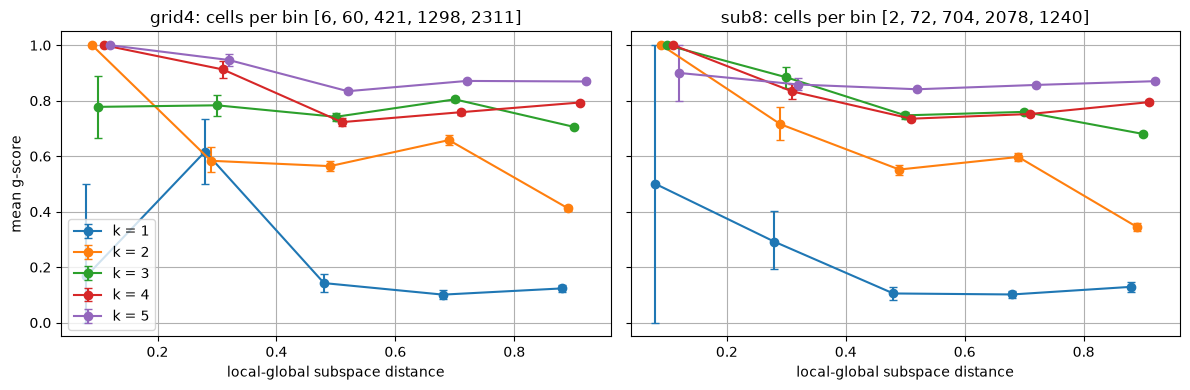

In [14]:
def g_scores(rank, glob, dist, kmax=5, nboot=1000, rng=None):
    """Mean g-score (Eq. 3.4) per distance bin of width 0.2, with 95 % bootstrap intervals over the cells of a bin."""
    out = np.full((kmax, 5, 3), np.nan)
    b = np.clip((dist / 0.2).astype(int), 0, 4)
    for k in range(1, kmax + 1):
        g = np.array([len(set(r[:k]) & set(glob[:k])) / k for r in rank])
        for j in range(5):
            gj = g[b == j]
            if len(gj) == 0:
                continue
            bs = gj[rng.integers(0, len(gj), (nboot, len(gj)))].mean(axis=1)
            out[k - 1, j] = gj.mean(), *np.percentile(bs, [2.5, 97.5])
    return out, np.bincount(b, minlength=5)


rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, L) in zip(axes, (('grid4', L4), ('sub8', L8))):
    gs, nb = g_scores(L['rank'], glob_rank, L['dist'], rng=rng)
    mid = np.arange(5) * 0.2 + 0.1
    for k in range(5):
        ok = ~np.isnan(gs[k, :, 0])
        ax.errorbar(mid[ok] + (k - 2) * 0.01, gs[k, ok, 0], yerr=[gs[k, ok, 0] - gs[k, ok, 1], gs[k, ok, 2] - gs[k, ok, 0]],
                    marker='o', capsize=3, label=f'k = {k + 1}')
        print(f'{name} k = {k + 1}: ' + ', '.join(f'[{0.2 * j:.1f}, {0.2 * j + 0.2:.1f}) ' +
              (f'{gs[k, j, 0]:.3f} [{gs[k, j, 1]:.3f}, {gs[k, j, 2]:.3f}]' if nb[j] else 'empty') for j in range(5)))
    ax.set_xlabel('local-global subspace distance')
    ax.set_title(f'{name}: cells per bin {nb.tolist()}')
    ax.grid(True)
axes[0].set_ylabel('mean g-score')
axes[0].legend()
fig.tight_layout()
plt.close(fig)
fig

The sub8 curves have the paper's shape: agreement on the single most influential input is low at every distance above 0.2 (0.292 for 0.2–0.4, about 0.10–0.13 beyond), and for $k = 2$ it falls from 0.715 (0.2–0.4) to 0.344 [0.330, 0.359] for distances 0.8–1.0, where the paper reports 36 % (p. 2193). The paper's values for the lowest bin (54 % for $k = 1$, about 76 % for $k = 2$, from 63 cells) cannot be checked here: only 2 of our sub8 cells fall in it (one of them the named cell of p. 2201, added by hand), so its intervals span the whole range. Larger $k$ agree more at every distance above 0.2 (0.680–0.884 for $k = 3$ to 5), as in the paper.

#### Secondary QoI

For the final Type S fraction $q_{\mathrm{sec}}$ (Eq. (3.5)) we estimate the global subspace from grid4 and repeat the local distances. In a cell where one population dies out at every point, $q_{\mathrm{sec}}$ is 0 or 1 to rounding and its 25 gradients underflow; such a cell has no subspace, and we leave it out (trace of $\tilde{\mathbf C}$ below $10^{-12}$ of the median trace). The paper does not say how it treated these cells.

q_sec eigenvalues [2.9823 0.9688 0.8613 0.2695 0.0379 0.0184]; ratios 3.08, 1.12, 3.20, 7.10, 2.07
q_sec w1 = [ 0.085 -0.18   0.815 -0.539  0.055 -0.046]
q_sec normalized activity scores (Eq. 2.2): [0.4246 0.4459 1.     0.5331 0.0224 0.0161]


q_sec grid4: mean local-global distance 0.6385 over 3870 cells (paper, 8^6 cells: 0.6369, p. 2198); 226 cells where q_sec is flat to rounding (all 25 gradients below 1e-12 of the median trace) are left out; local n counts (1..6) [2693 1128   49    0    0    0]


q_sec sub8: mean local-global distance 0.6316 over 3605 cells (paper, 8^6 cells: 0.6369, p. 2198); 491 cells where q_sec is flat to rounding (all 25 gradients below 1e-12 of the median trace) are left out; local n counts (1..6) [3031  570    4    0    0    0]


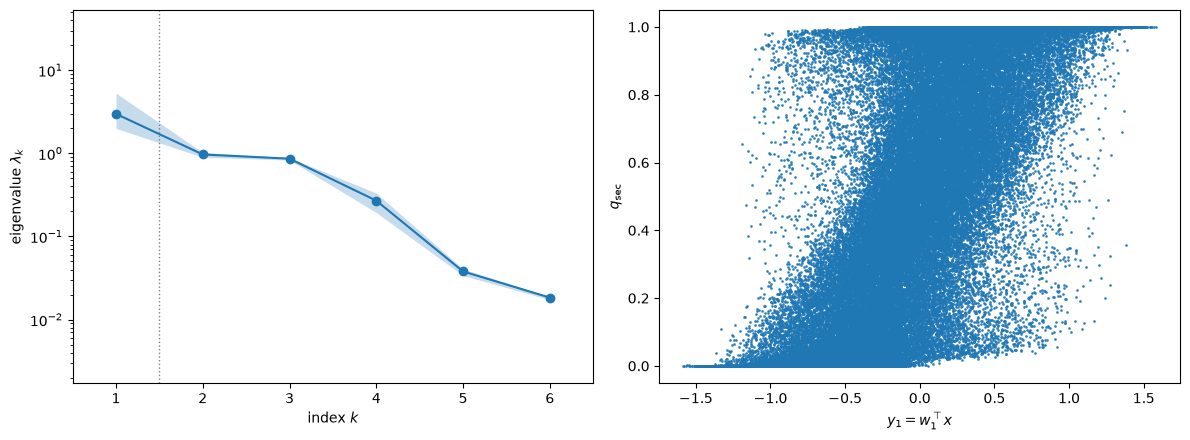

In [15]:
sub_s = ac.active_subspace(space=space, X=X4, f=f4[:, 1], grads=G4[:, 1], estimator='as', nboot=200, rng=SEED)
sub_s = ac.orient(sub_s, by='covariance', X=X4, f=f4[:, 1], columns=6)
lam_s = sub_s.eigenvalues
print(f'q_sec eigenvalues {np.array2string(lam_s, precision=4)}; ratios ' +
      ', '.join(f'{lam_s[k] / lam_s[k + 1]:.2f}' for k in range(5)))
print(f'q_sec w1 = {np.array2string(sub_s.W[:, 0], precision=3, suppress_small=True)}')
print(f'q_sec normalized activity scores (Eq. 2.2): {np.array2string(act_scores(G4[:, 1]), precision=4)}')
for name, G in (('grid4', G4), ('sub8', G8)):
    Ls = local_analysis(G[:, 1], sub_s.W)
    print(f'q_sec {name}: mean local-global distance {np.nanmean(Ls["dist"]):.4f} over {int((~Ls["flat"]).sum())} cells '
          f'(paper, 8^6 cells: 0.6369, p. 2198); {int(Ls["flat"].sum())} cells where q_sec is flat to rounding '
          f'(all 25 gradients below 1e-12 of the median trace) are left out; local n counts (1..6) {np.bincount(Ls["n"], minlength=7)[1:]}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_eigenvalues(sub_s, ax=axes[0])
ac.plotting.plot_sufficient_summary(sub_s, X=X4, f=f4[:, 1], dims=1, qoi_label=r'$q_{\mathrm{sec}}$', ax=axes[1])
for c in axes[1].collections:
    c.set_sizes([1])
fig.tight_layout()
plt.close(fig)
fig

The $q_{\mathrm{sec}}$ spectrum has no large gap (ratios 3.08, 1.12, 3.20, 7.10, 2.07); $\mathbf w_1$ is dominated by the carrying capacities, $K_S$ (0.815) against $K_R$ ($-0.539$), and the summary plot shows the saturation at 0 and 1. The mean local–global distance on the sub8 cells is 0.6316 over 3605 cells (491 flat cells left out), against the paper's 0.6369 (p. 2198); on grid4 it is 0.6385.

#### Surrogate on the active variables

A quadratic in the four active variables, fitted to the 102,400 grid4 points and tested on the independent sub8 points.

quadratic in n = 4: LOO R^2 = 0.9170 (grid4), R^2 on the independent sub8 points 0.9174


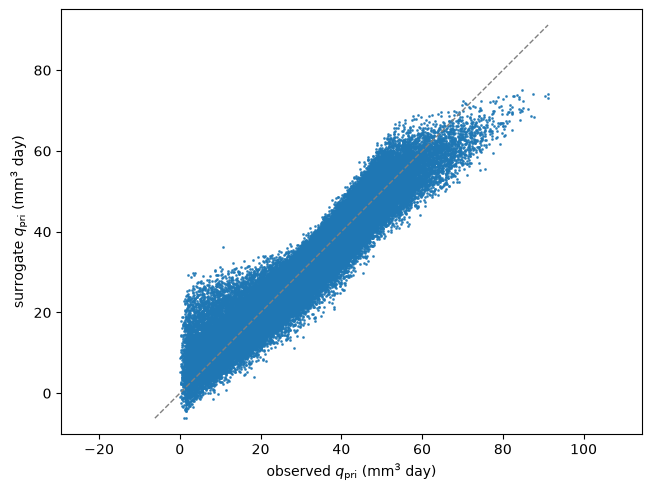

In [16]:
sur = ac.fit_surrogate(X=X4, f=f4[:, 0], subspace=sub, kind='poly', degree=2)
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=X4, f=f4[:, 0], qoi_label=r'$q_{\mathrm{pri}}$ (mm$^3$ day)')
for c in ax.collections:
    c.set_sizes([1])
plt.close(fig)
pred = ac.predict(sur, X8)
r2_8 = 1 - np.sum((pred - f8[:, 0]) ** 2) / np.sum((f8[:, 0] - f8[:, 0].mean()) ** 2)
print(f'quadratic in n = {N_CHOSEN}: LOO R^2 = {sur.loo_r_squared:.4f} (grid4), R^2 on the independent sub8 points {r2_8:.4f}')
fig

The quadratic has leave-one-out $R^2 = 0.9170$ on grid4 and $R^2 = 0.9174$ on the sub8 points, so it generalizes but leaves about 8 % of the variance; the paper's point (Sec. 3.3.2) is that local surrogates on local subspaces do better where the local–global distance is large.

### Comparison with the paper

The paper's results come from MATLAB with forward-difference gradients (step $10^{-5}$) on `ode45` solves, on all $8^6$ cells with 25 points each; ours from exact sensitivities, on the $4^6$ grid4 cells and a random 4096 of the $8^6$ cells. Not reproduced here: the Morris and Sobol' results of Tables 1–2, the bifurcation-matched distances (Figs. 10–11, means 0.6650, 0.7010, 0.6513 and 0.6665, p. 2197; the paper does not say how a cell whose points have different long-term outcomes is matched), the bootstrap studies of Figs. 8–9, and the calibration and surrogate experiments of Sec. 3.3.

| Quantity | Paper value | Notebook value |
|---|---|---|
| $\alpha_i/\alpha_{\max}$, $r_S, r_R, K_S, K_R, \gamma_S, \gamma_R$ | 1.0000, 0.6715, 0.9364, 0.6942, 0.0746, 0.0567 (Table 1, p. 2188) | 1.0000, 0.6690, 0.9347, 0.6934, 0.0745, 0.0568 (grid4; paper inside every 95 % interval) |
| Global activity-score ranking | $r_S, K_S, K_R, r_R, \gamma_S, \gamma_R$ (p. 2188) | the same (grid4 and sub8) |
| Most frequent local ranking (share of cells) | $K_R, r_R, K_S, \gamma_S, \gamma_R, r_S$, 4.70 % (Table 2) | the same, 4.37 % (sub8) |
| Rank and share of the global ranking among local rankings | 53rd, 0.58 % (p. 2188) | 41st, 0.68 % (sub8); 27th, 1.17 % (grid4) |
| Distinct local rankings | 304 of 262,144 cells (p. 2188) | 230 of 4096 cells (sub8; not comparable) |
| Cells per distance bin 0–0.2, …, 0.8–1.0 | 0.024, 1.664, 17.143, 50.784, 30.385 % (63, 4362, 44,939, 133,127, 79,653 cells; p. 2192) | 0.024, 1.759, 17.196, 50.757, 30.264 % (1, 72, 704, 2078, 1239 of the 4094 random sub8 cells) |
| Mean local–global distance, $q_{\mathrm{pri}}$ | 0.7334 (p. 2197) | 0.73048 (4094 random sub8 cells; 0.73040 with the two named cells); 0.82183 (grid4) |
| Distance, cell of p. 2201 / top cell $[0.875, 1]^6$ | 0.1355 / 0.9996 (p. 2201) | 0.1332 / 0.9997 |
| Mean g-score, $k = 2$, distances 0.8–1.0 | 36 % (p. 2193) | 0.344 [0.330, 0.359] (sub8) |
| Mean g-score, distances 0–0.2, $k = 1$ / $k = 2$ | 54 % / ≈ 76 % (p. 2193) | 2 cells only (1 random), not estimable |
| Stable-equilibrium shares | 25 %, 25 %, 50 % (Table 3, p. 2196) | 25.03 %, 24.94 %, 50.03 % (grid4); exact 25, 25, 50 % |
| Mean local–global distance, $q_{\mathrm{sec}}$ | 0.6369 (p. 2198) | 0.6316 (sub8, 491 flat cells left out) |
| Global active subspace dimension | not reported | $n = 4$, $\lambda_4/\lambda_5 = 8.97$ |
| Quadratic surrogate on $n = 4$ active variables | not reported | LOO $R^2 = 0.9170$ |

The agreement is close where the comparison is like for like. The activity scores agree within the Monte Carlo error of our 102,400 points; the paper's 6.5 million points make its values more precise than ours, and its forward differences (step $10^{-5}$, `ode45` at rtol $10^{-6}$) differ from exact gradients by a median relative error of $3.2\times10^{-5}$ (largest $8.6\times10^{-4}$ over 100 points; `check_accuracy.py`, check 4), too little to matter for the scores. The sub8 distance shares (on the randomly drawn cells) and the leading local rankings agree with the paper's full sweep within the sampling error of a 1/64 subset of cells; the grid4 cells, four times as wide in each input, give systematically larger distances, so the cell size matters for the paper's diagnostics.

### References

[1] H. Zou and A. L. Lewis. [Using active subspaces to explore discrepancies between global and local parameter sensitivities in a Lotka-Volterra system](https://doi.org/10.3934/mbe.2026079). *Mathematical Biosciences and Engineering*, 23(7):2178–2207, 2026. The authors' MATLAB sample code is at <https://github.com/lewisallison10/Global-vs.-Local-Sensitivity-Using-the-Active-Subspace> (no licence; read for the settings, not copied).

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] H. Cho, A. L. Lewis, K. M. Storey, and H. M. Byrne. [Designing experimental conditions to use the Lotka–Volterra model to infer tumor cell line interaction types](https://doi.org/10.1016/j.jtbi.2022.111377). *Journal of Theoretical Biology*, 559:111377, 2023.

[4] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[R1]: https://doi.org/10.3934/mbe.2026079
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1016/j.jtbi.2022.111377
[R4]: https://doi.org/10.1016/j.ress.2017.01.013

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 34.7 s
